# HausaSentiment: Transformer-Based Sentiment Classification for Hausa

## Project Overview

This notebook develops and evaluates a machine learning system for three-class sentiment classification of Hausa text.

The project follows a research-oriented workflow:

1. Obtain and document a real-world Hausa sentiment dataset.
2. Inspect and assess the quality of the data.
3. Perform appropriate preprocessing.
4. Establish a TF-IDF + Logistic Regression baseline.
5. Fine-tune a multilingual Transformer model, XLM-RoBERTa.
6. Conduct controlled experiments on important training choices.
7. Evaluate the final model using accuracy, precision, recall, and F1-score.
8. Analyze successful and unsuccessful predictions.
9. Save the final model for deployment through a web application.

The notebook is designed to satisfy the requirements for dataset preparation, model development, baseline comparison, experimentation, evaluation, error analysis, reproducibility, and deployment preparation.

In [1]:
#Connect to google drive

from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
#Creating project paths

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/hausa_sentiment_classifier")

DATA_DIR = PROJECT_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"

MODEL_DIR = PROJECT_DIR / "models"

for directory in [
    DATA_DIR,
    RAW_DIR,
    PROCESSED_DIR,
    RESULTS_DIR,
    FIGURES_DIR,
    TABLES_DIR,
    MODEL_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)

Project directory: /content/drive/MyDrive/hausa_sentiment_classifier


## 1. Computing Environment

Transformer fine-tuning is computationally more demanding than the baseline model. Therefore, the Transformer experiments will be conducted using a GPU in Google Colab.

The baseline TF-IDF + Logistic Regression model does not require a GPU and will run on the CPU.

Before training any Transformer model, we verify that a CUDA-enabled GPU is available and record the environment information for reproducibility.

In [3]:
#Checking GPU

import torch
import platform
import sys

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("WARNING: GPU is not available.")
    print("Go to Runtime > Change runtime type > Hardware accelerator > GPU")

Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0


## 2. Libraries and Dependencies

The project uses established NLP and machine learning libraries for data processing, classical machine learning, Transformer fine-tuning, evaluation, and visualization.

The main modeling approaches are:

- TF-IDF + Logistic Regression as the baseline.
- XLM-RoBERTa as the proposed Transformer-based approach.

The required packages are installed explicitly to make the computational environment reproducible.

In [4]:
!pip -q install -U \
    transformers \
    datasets \
    accelerate \
    sentencepiece \
    evaluate \
    scikit-learn \
    seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 103.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 41.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 87.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 19.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 25.0.1 which is incompatible.


In [5]:
#Import Libraries

import os
import re
import json
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    f1_score
)

import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

from datasets import Dataset, DatasetDict

warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Reproducibility

Machine learning experiments can produce slightly different results when random initialization, data shuffling, or other stochastic operations change.

A fixed random seed is therefore used throughout the project where possible. This allows the experiments to be repeated under the same computational conditions and makes comparisons between models more meaningful.

In [6]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)

Random seed: 42


# 4. Dataset Acquisition

## AfriSenti Hausa Dataset

The project uses the Hausa portion of the AfriSenti benchmark.

AfriSenti is a large sentiment analysis benchmark covering 14 African languages. The data consists of real-world tweets that were annotated for sentiment, making it appropriate for investigating sentiment classification in an under-resourced African language.

The Hausa dataset contains three sentiment categories:

- Positive
- Negative
- Neutral

The original dataset provides separate training, development/validation, and test sets. We preserve these official splits rather than randomly creating a new test set.

This is important because the test set should remain unseen during model development and hyperparameter selection.

In [7]:
import requests

BASE_URL = (
    "https://raw.githubusercontent.com/"
    "afrisenti-semeval/afrisent-semeval-2023/main/data/hau"
)

files = {
    "train": RAW_DIR / "train.tsv",
    "dev": RAW_DIR / "dev.tsv",
    "test": RAW_DIR / "test.tsv"
}

for split, path in files.items():
    url = f"{BASE_URL}/{path.name}"

    response = requests.get(url)
    response.raise_for_status()

    path.write_bytes(response.content)

    print(f"Downloaded {split}: {path}")

Downloaded train: /content/drive/MyDrive/hausa_sentiment_classifier/data/raw/train.tsv
Downloaded dev: /content/drive/MyDrive/hausa_sentiment_classifier/data/raw/dev.tsv
Downloaded test: /content/drive/MyDrive/hausa_sentiment_classifier/data/raw/test.tsv


In [8]:
#Load the dataset

train_df = pd.read_csv(files["train"], sep="\t")
val_df = pd.read_csv(files["dev"], sep="\t")
test_df = pd.read_csv(files["test"], sep="\t")

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

Train shape: (14172, 2)
Validation shape: (2677, 2)
Test shape: (5303, 2)


In [9]:
#Data schema

print("Train columns:", train_df.columns.tolist())
print("\nFirst 5 rows:")
display(train_df.head())

Train columns: ['tweet', 'label']

First 5 rows:


,tweet,label
0,@user Da kudin da Arewa babu wani abin azo aga...,negative
1,@user Kaga wani Adu ar Banda💔😭 wai a haka Shi ...,negative
2,@user Sai haquri fa yan madrid daman kunce cha...,negative
3,@user Hmmm yanzu kai kasan girman allah daxaka...,negative
4,@user @user Wai gwamno nin Nigeria suna afa kw...,negative


In [10]:
print("\nData types:")
print(train_df.dtypes)

print("\nMissing values:")
print(train_df.isna().sum())


Data types:
tweet    object
label    object
dtype: object

Missing values:
tweet    0
label    0
dtype: int64


## 5. Initial Data Quality Assessment

Before training a model, the dataset must be inspected for common quality problems.

The following checks are performed:

- missing text
- missing labels
- duplicate texts
- unexpected labels
- empty strings
- class distribution
- unusually short or long texts

These checks help determine whether preprocessing is necessary and provide evidence for discussing the quality and limitations of the dataset.

In [11]:
LABELS = ["positive", "negative", "neutral"]

for name, df in {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}.items():

    print(f"\n===== {name.upper()} =====")

    print("Rows:", len(df))
    print("Missing tweets:", df["tweet"].isna().sum())
    print("Missing labels:", df["label"].isna().sum())
    print("Duplicate tweets:", df["tweet"].duplicated().sum())
    print("Unique labels:", sorted(df["label"].dropna().unique()))


===== TRAIN =====
Rows: 14172
Missing tweets: 0
Missing labels: 0
Duplicate tweets: 0
Unique labels: ['negative', 'neutral', 'positive']

===== VALIDATION =====
Rows: 2677
Missing tweets: 0
Missing labels: 0
Duplicate tweets: 0
Unique labels: ['negative', 'neutral', 'positive']

===== TEST =====
Rows: 5303
Missing tweets: 0
Missing labels: 0
Duplicate tweets: 0
Unique labels: ['negative', 'neutral', 'positive']


In [12]:
#Removing only problematic records

def basic_clean_dataframe(df):
    df = df.copy()

    # Remove missing values
    df = df.dropna(subset=["tweet", "label"])

    # Convert to string
    df["tweet"] = df["tweet"].astype(str)
    df["label"] = df["label"].astype(str).str.lower().str.strip()

    # Remove completely empty text
    df = df[df["tweet"].str.strip().ne("")]

    # Remove exact duplicate texts
    df = df.drop_duplicates(subset=["tweet"])

    return df.reset_index(drop=True)


train_df = basic_clean_dataframe(train_df)
val_df = basic_clean_dataframe(val_df)
test_df = basic_clean_dataframe(test_df)

print("After basic cleaning:")
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

After basic cleaning:
Train: (14172, 2)
Validation: (2677, 2)
Test: (5303, 2)


label
neutral     4912
positive    4687
negative    4573
Name: count, dtype: int64


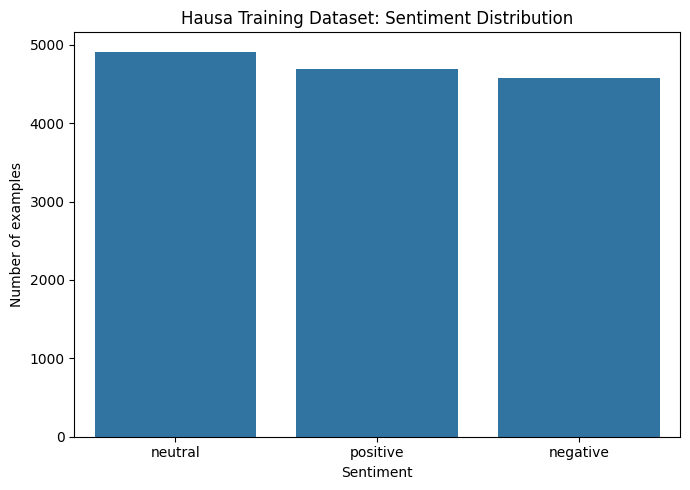

In [13]:
#Class Distribution

label_counts = train_df["label"].value_counts()

print(label_counts)

plt.figure(figsize=(7, 5))
sns.barplot(
    x=label_counts.index,
    y=label_counts.values
)

plt.title("Hausa Training Dataset: Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of examples")
plt.tight_layout()

distribution_path = FIGURES_DIR / "class_distribution.png"
plt.savefig(distribution_path, dpi=300, bbox_inches="tight")
plt.show()

In [14]:
#Checking class imbalance

class_distribution = (
    train_df["label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(class_distribution)

label
neutral     34.66
positive    33.07
negative    32.27
Name: proportion, dtype: float64


In [15]:
#Text length analysis

train_df["text_length"] = train_df["tweet"].str.split().str.len()

print(train_df["text_length"].describe())

count    14172.000000
mean        14.015665
std          9.655730
min          4.000000
25%          7.000000
50%         11.000000
75%         17.000000
max         58.000000
Name: text_length, dtype: float64


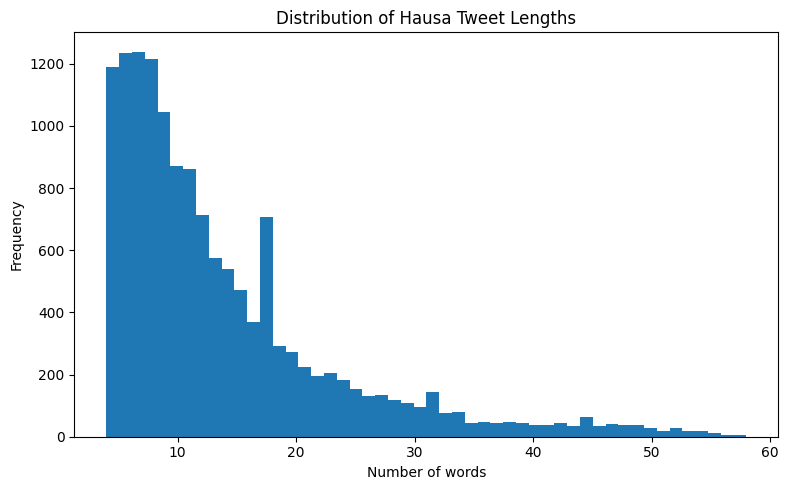

In [16]:
plt.figure(figsize=(8, 5))

plt.hist(
    train_df["text_length"],
    bins=50
)

plt.title("Distribution of Hausa Tweet Lengths")
plt.xlabel("Number of words")
plt.ylabel("Frequency")

plt.tight_layout()

length_path = FIGURES_DIR / "text_length_distribution.png"
plt.savefig(length_path, dpi=300, bbox_inches="tight")
plt.show()

In [17]:
#Examples of actual data

display(
    train_df[
        ["tweet", "label"]
    ].sample(
        10,
        random_state=SEED
    )
)

,tweet,label
3448,@user I hate 😡 u rahama as actress,negative
13026,@user Yayi ango Allah ya Kara lfy🤲🤲🤲🤲👍👍,positive
9002,@user Too pah sabon mawaki mukayi 😃😹😹,neutral
12541,@user Annabin Rahma ya karbi bakuncin_sa Ameen 🕌🕋,positive
10298,@user Haka yake Allah karda na nuna ma yan naj...,positive
10098,@user @user @user @user @user @user @user Haj....,positive
4536,@user Dn uwarsu ba😒,negative
7113,@user @user @user Jide Sanwolu ba na ji Hausa 😁,neutral
3233,@user Wannan cuta akwai rashin kunya dai😂😂 @user,negative
7671,@user Aisu shuwagaban nin sun san yadda aka sa...,neutral


In [18]:
#Prepare labels

label2id = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

id2label = {
    0: "negative",
    1: "neutral",
    2: "positive"
}

for df in [train_df, val_df, test_df]:
    df["label_id"] = df["label"].map(label2id)

print(train_df[["tweet", "label", "label_id"]].head())

                                               tweet     label  label_id
0  @user Da kudin da Arewa babu wani abin azo aga...  negative         0
1  @user Kaga wani Adu ar Banda💔😭 wai a haka Shi ...  negative         0
2  @user Sai haquri fa yan madrid daman kunce cha...  negative         0
3  @user Hmmm yanzu kai kasan girman allah daxaka...  negative         0
4  @user @user Wai gwamno nin Nigeria suna afa kw...  negative         0


In [19]:
print("Unknown labels:")
print(train_df[train_df["label_id"].isna()]["label"].unique())

Unknown labels:
[]


# 6. Baseline Model: TF-IDF + Logistic Regression

A classical machine learning baseline is established before introducing the Transformer model.

TF-IDF represents each document using weighted word or n-gram features. Logistic Regression then learns a classifier from these features.

This baseline is intentionally simpler than XLM-RoBERTa. Its purpose is not necessarily to achieve the highest performance, but to provide a meaningful reference point against which the Transformer model can be evaluated.

The baseline is trained only on the training set. Hyperparameter decisions are made using the validation set, while the test set remains untouched until final evaluation.

In [20]:
#TF-IDF

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train = tfidf.fit_transform(train_df["tweet"])
X_val = tfidf.transform(val_df["tweet"])
X_test = tfidf.transform(test_df["tweet"])

y_train = train_df["label_id"]
y_val = val_df["label_id"]
y_test = test_df["label_id"]

print("Training matrix:", X_train.shape)
print("Validation matrix:", X_val.shape)
print("Test matrix:", X_test.shape)

Training matrix: (14172, 25256)
Validation matrix: (2677, 25256)
Test matrix: (5303, 25256)


In [21]:
#Train baseline

baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=SEED
)

baseline_model.fit(X_train, y_train)

baseline_val_pred = baseline_model.predict(X_val)

In [22]:
#Baseline Metrics

baseline_accuracy = accuracy_score(
    y_val,
    baseline_val_pred
)

baseline_precision, baseline_recall, baseline_f1, _ = (
    precision_recall_fscore_support(
        y_val,
        baseline_val_pred,
        average="weighted",
        zero_division=0
    )
)

baseline_results = {
    "model": "TF-IDF + Logistic Regression",
    "accuracy": baseline_accuracy,
    "precision_weighted": baseline_precision,
    "recall_weighted": baseline_recall,
    "f1_weighted": baseline_f1
}

baseline_results

{'model': 'TF-IDF + Logistic Regression',
 'accuracy': 0.7527082555098992,
 'precision_weighted': 0.7598346432981898,
 'recall_weighted': 0.7527082555098992,
 'f1_weighted': 0.754364786649673}

In [23]:
print(
    classification_report(
        y_val,
        baseline_val_pred,
        target_names=[
            id2label[i] for i in range(3)
        ],
        digits=4
    )
)

              precision    recall  f1-score   support

    negative     0.7351    0.6890    0.7113       894
     neutral     0.6699    0.7679    0.7155       896
    positive     0.8756    0.8016    0.8370       887

    accuracy                         0.7527      2677
   macro avg     0.7602    0.7528    0.7546      2677
weighted avg     0.7598    0.7527    0.7544      2677



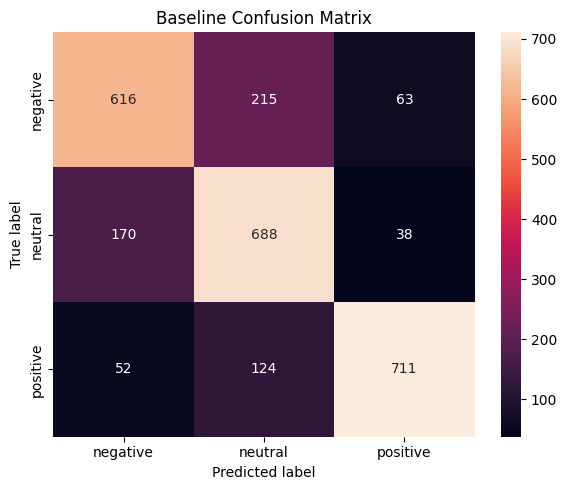

In [24]:
#Baseline confusion matrix

cm = confusion_matrix(
    y_val,
    baseline_val_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=[id2label[i] for i in range(3)],
    yticklabels=[id2label[i] for i in range(3)]
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Baseline Confusion Matrix")

plt.tight_layout()

baseline_cm_path = FIGURES_DIR / "baseline_confusion_matrix.png"
plt.savefig(
    baseline_cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 7. Transformer Model: XLM-RoBERTa

The proposed model is XLM-RoBERTa-base, a multilingual Transformer pretrained on multiple languages.

XLM-R is selected because Hausa is a relatively under-resourced language compared with English, and multilingual pretrained representations provide a practical starting point for transferring general language knowledge to Hausa.

The pretrained model is adapted to the project-specific three-class sentiment task by replacing/using its classification head and fine-tuning the model on the Hausa training data.

Input:
    Hausa text

Tokenizer:
    XLM-RoBERTa tokenizer

Encoder:
    XLM-RoBERTa Transformer

Classification head:
    Three output logits

Output:
    Negative / Neutral / Positive

In [25]:
#Tokenizer

MODEL_NAME = "xlm-roberta-base"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

print("Tokenizer:", MODEL_NAME)
print("Vocabulary size:", tokenizer.vocab_size)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Tokenizer: xlm-roberta-base
Vocabulary size: 250002


In [26]:
#Tokenization example

example_text = train_df.iloc[0]["tweet"]

encoded = tokenizer(
    example_text,
    truncation=True,
    max_length=128
)

print("Original text:")
print(example_text)

print("\nToken IDs:")
print(encoded["input_ids"][:30])

print("\nTokens:")
print(tokenizer.convert_ids_to_tokens(
    encoded["input_ids"][:30]
))

Original text:
@user Da kudin da Arewa babu wani abin azo agani da yayi wa alummah allah ya isa yacucemu wlh yarikitamana kasa yarikitamana kasuwanci harkar ilimi harkar lfy hanyoyi babu lantarki dasuransu komai yalalace ga cinhanci da rashawa a fili ko ina a Nigeria jamiyaryar su tabataman mlm 😭🗣

Token IDs:
[0, 1374, 65918, 930, 228, 3035, 48, 196867, 106075, 27534, 75718, 295, 31, 10, 45055, 48, 127483, 259, 144, 316, 12230, 6, 40077, 151, 25412, 151, 1010, 329, 561, 148]

Tokens:
['<s>', '▁@', 'user', '▁Da', '▁ku', 'din', '▁da', '▁Arewa', '▁babu', '▁wani', '▁abin', '▁az', 'o', '▁a', 'gani', '▁da', '▁yayi', '▁wa', '▁al', 'um', 'mah', '▁', 'allah', '▁ya', '▁isa', '▁ya', 'cu', 'ce', 'mu', '▁w']


In [27]:
#Convert dataset

train_hf = Dataset.from_pandas(
    train_df[["tweet", "label_id"]].rename(
        columns={"label_id": "labels"}
    ),
    preserve_index=False
)

val_hf = Dataset.from_pandas(
    val_df[["tweet", "label_id"]].rename(
        columns={"label_id": "labels"}
    ),
    preserve_index=False
)

test_hf = Dataset.from_pandas(
    test_df[["tweet", "label_id"]].rename(
        columns={"label_id": "labels"}
    ),
    preserve_index=False
)

dataset = DatasetDict({
    "train": train_hf,
    "validation": val_hf,
    "test": test_hf
})

dataset

DatasetDict({
    train: Dataset({
        features: ['tweet', 'labels'],
        num_rows: 14172
    })
    validation: Dataset({
        features: ['tweet', 'labels'],
        num_rows: 2677
    })
    test: Dataset({
        features: ['tweet', 'labels'],
        num_rows: 5303
    })
})

In [28]:
#Tokenize

MAX_LENGTH = 128

def tokenize_batch(batch):
    return tokenizer(
        batch["tweet"],
        truncation=True,
        max_length=MAX_LENGTH
    )

tokenized_dataset = dataset.map(
    tokenize_batch,
    batched=True,
    desc="Tokenizing Hausa text"
)

print(tokenized_dataset)

Tokenizing Hausa text:   0%|          | 0/14172 [00:00<?, ? examples/s]

Tokenizing Hausa text:   0%|          | 0/2677 [00:00<?, ? examples/s]

Tokenizing Hausa text:   0%|          | 0/5303 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['tweet', 'labels', 'input_ids', 'attention_mask'],
        num_rows: 14172
    })
    validation: Dataset({
        features: ['tweet', 'labels', 'input_ids', 'attention_mask'],
        num_rows: 2677
    })
    test: Dataset({
        features: ['tweet', 'labels', 'input_ids', 'attention_mask'],
        num_rows: 5303
    })
})


In [29]:
#MODEL

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

print("Model loaded:", MODEL_NAME)
print("Number of labels:", model.config.num_labels)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded: xlm-roberta-base
Number of labels: 3


# 8. Evaluation Metrics

The project uses accuracy, weighted precision, weighted recall, and weighted F1-score.

Accuracy measures the proportion of predictions that are correct.

Precision measures how often predictions assigned to a class are correct.

Recall measures how effectively the model identifies examples belonging to a class.

F1-score combines precision and recall and is particularly useful when class distributions are not perfectly balanced.

Weighted F1 is reported as the primary aggregate metric because it accounts for the number of examples in each class while still reflecting performance across all three sentiment categories.

In [30]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    accuracy = accuracy_score(
        labels,
        predictions
    )

    return {
        "accuracy": accuracy,
        "precision_weighted": precision,
        "recall_weighted": recall,
        "f1_weighted": f1
    }

In [31]:
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

In [47]:
#First XLM-R run

total_steps = (len(train_df) // 16) * 6
warmup_steps = int(total_steps * 0.1)

training_args = TrainingArguments(
    output_dir=str(MODEL_DIR / "xlmr_baseline_run"),

    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,

    num_train_epochs=6,

    weight_decay=0.01,
    warmup_steps=warmup_steps,

    logging_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="f1_weighted",
    greater_is_better=True,

    fp16=torch.cuda.is_available(),

    seed=SEED,

    report_to="none"
)

In [48]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

In [49]:

train_output = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision Weighted,Recall Weighted,F1 Weighted
1,0.262365,1.008970,0.744490,0.745880,0.744490,0.744348
2,0.221314,1.404457,0.742996,0.744010,0.742996,0.740973
3,0.348468,0.801122,0.745237,0.746278,0.745237,0.740425
4,0.314168,0.781554,0.755697,0.754753,0.755697,0.755168
5,0.237877,1.000595,0.758312,0.758024,0.758312,0.758137
6,0.202840,1.105706,0.752708,0.752445,0.752708,0.752472


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [51]:
from pathlib import Path

print("MODEL_DIR:", MODEL_DIR)

if MODEL_DIR.exists():
    for path in sorted(MODEL_DIR.iterdir()):
        if path.is_dir():
            size = sum(f.stat().st_size for f in path.rglob("*") if f.is_file())
            print(f"{path.name}: {size / (1024**3):.2f} GB")
        else:
            print(f"{path.name}: {path.stat().st_size / (1024**3):.2f} GB")
else:
    print("MODEL_DIR does not exist.")

MODEL_DIR: /content/drive/MyDrive/hausa_sentiment_classifier/models
xlmr_baseline_run: 18.74 GB


In [54]:
import json

best_checkpoint = MODEL_DIR / "xlmr_baseline_run" / "checkpoint-4430"

with open(best_checkpoint / "trainer_state.json", "r") as f:
    state = json.load(f)

print("Best checkpoint:", state["best_model_checkpoint"])
print("Best weighted F1:", state["best_metric"])

print("\nTraining history:")
for item in state["log_history"]:
    print(item)

Best checkpoint: /content/drive/MyDrive/hausa_sentiment_classifier/models/xlmr_baseline_run/checkpoint-4430
Best weighted F1: 0.7581365857168185

Training history:
{'epoch': 1.0, 'grad_norm': 29.628097534179688, 'learning_rate': 1.8520376175548592e-05, 'loss': 0.26236516465990056, 'step': 886}
{'epoch': 1.0, 'eval_accuracy': 0.7444901008591707, 'eval_f1_weighted': 0.7443478693233662, 'eval_loss': 1.008970022201538, 'eval_precision_weighted': 0.745880070382604, 'eval_recall_weighted': 0.7444901008591707, 'eval_runtime': 3.1942, 'eval_samples_per_second': 838.09, 'eval_steps_per_second': 26.298, 'step': 886}
{'epoch': 2.0, 'grad_norm': 78.83726501464844, 'learning_rate': 1.4817136886102406e-05, 'loss': 0.2213135454509382, 'step': 1772}
{'epoch': 2.0, 'eval_accuracy': 0.7429958909226746, 'eval_f1_weighted': 0.740972714796448, 'eval_loss': 1.404457449913025, 'eval_precision_weighted': 0.7440103765583854, 'eval_recall_weighted': 0.7429958909226746, 'eval_runtime': 3.9474, 'eval_samples_per_

In [57]:
#Validation results

xlmr_val_results = trainer.evaluate(
    tokenized_dataset["validation"]
)

xlmr_val_results

Training Loss,Validation Loss,Epoch,Accuracy,Precision Weighted,Recall Weighted,F1 Weighted
0.202840,1.000595,6,0.758312,0.758024,0.758312,0.758137


{'eval_loss': 1.000595211982727,
 'eval_accuracy': 0.7583115427717594,
 'eval_precision_weighted': 0.7580240760866168,
 'eval_recall_weighted': 0.7583115427717594,
 'eval_f1_weighted': 0.7581365857168185}

In [58]:
#Baseline vrs Transformer

comparison = pd.DataFrame([
    baseline_results,
    {
        "model": "XLM-RoBERTa-base",
        "accuracy": xlmr_val_results["eval_accuracy"],
        "precision_weighted": xlmr_val_results["eval_precision_weighted"],
        "recall_weighted": xlmr_val_results["eval_recall_weighted"],
        "f1_weighted": xlmr_val_results["eval_f1_weighted"]
    }
])

display(comparison)

,model,accuracy,precision_weighted,recall_weighted,f1_weighted
0,TF-IDF + Logistic Regression,0.752708,0.759835,0.752708,0.754365
1,XLM-RoBERTa-base,0.758312,0.758024,0.758312,0.758137


In [59]:
comparison.to_csv(
    TABLES_DIR / "baseline_vs_xlmr.csv",
    index=False
)

# 9. Controlled Hyperparameter Experiment

### Research Question

How does the learning rate affect the performance of XLM-RoBERTa on Hausa sentiment classification?

### Experimental Design

Three learning rates are compared:

- 1e-5
- 2e-5
- 3e-5

All other training conditions remain fixed.

This isolates the effect of the learning rate and allows us to determine whether the model is sensitive to the size of parameter updates during fine-tuning.

The validation set is used for model selection. The test set remains untouched until the final evaluation.

In [63]:
LOCAL_MODEL_DIR = Path("/content/hausa_sentiment_models")
LOCAL_MODEL_DIR.mkdir(parents=True, exist_ok=True)

print(LOCAL_MODEL_DIR)

/content/hausa_sentiment_models


In [72]:
from pathlib import Path

# Use Colab's temporary local storage, NOT Google Drive
LOCAL_MODEL_DIR = Path("/content/xlmr_lr_experiments")
LOCAL_MODEL_DIR.mkdir(parents=True, exist_ok=True)

learning_rates = [1e-5, 2e-5, 3e-5]

experiment_results = []

for lr in learning_rates:

    print("\n" + "=" * 70)
    print(f"Training XLM-R with learning rate = {lr}")
    print("=" * 70)

    experiment_model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=3,
        id2label=id2label,
        label2id=label2id
    )

    # Calculate 10% warmup for 3 epochs
    total_steps = (len(train_df) // 16) * 3
    warmup_steps = int(total_steps * 0.1)

    experiment_args = TrainingArguments(
        # IMPORTANT: this is /content/, NOT Google Drive
        output_dir=str(LOCAL_MODEL_DIR / f"lr_{lr}"),

        eval_strategy="epoch",

        # IMPORTANT: DO NOT save checkpoints
        save_strategy="no",

        learning_rate=lr,

        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,

        num_train_epochs=3,

        weight_decay=0.01,
        warmup_steps=warmup_steps,

        logging_strategy="epoch",

        # No checkpoint saving = no loading best checkpoint
        load_best_model_at_end=False,

        fp16=torch.cuda.is_available(),

        seed=SEED,
        report_to="none"
    )

    experiment_trainer = Trainer(
        model=experiment_model,
        args=experiment_args,
        train_dataset=tokenized_dataset["train"],
        eval_dataset=tokenized_dataset["validation"],
        processing_class=tokenizer,
        data_collator=data_collator,
        compute_metrics=compute_metrics
    )

    experiment_trainer.train()

    results = experiment_trainer.evaluate()

    experiment_results.append({
        "learning_rate": lr,
        "accuracy": results["eval_accuracy"],
        "precision_weighted": results["eval_precision_weighted"],
        "recall_weighted": results["eval_recall_weighted"],
        "f1_weighted": results["eval_f1_weighted"]
    })

    print("\nResults:")
    print(experiment_results[-1])


Training XLM-R with learning rate = 1e-05


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision Weighted,Recall Weighted,F1 Weighted
1,0.859025,0.719189,0.676504,0.689020,0.676504,0.677944
2,0.697176,0.692358,0.710870,0.707658,0.710870,0.708268
3,0.621117,0.643210,0.728054,0.729328,0.728054,0.727768


Training Loss,Validation Loss,Epoch,Accuracy,Precision Weighted,Recall Weighted,F1 Weighted
0.621117,0.643210,3,0.728054,0.729328,0.728054,0.727768


...

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision Weighted,Recall Weighted,F1 Weighted
1,0.869449,0.709387,0.688831,0.688975,0.688831,0.688902
2,0.677981,0.630293,0.739260,0.742007,0.739260,0.739170
3,0.557088,0.602613,0.750840,0.754549,0.750840,0.751565


Training Loss,Validation Loss,Epoch,Accuracy,Precision Weighted,Recall Weighted,F1 Weighted
0.557088,0.602613,3,0.750840,0.754549,0.750840,0.751565



Results:
{'learning_rate': 3e-05, 'accuracy': 0.750840493089279, 'precision_weighted': 0.7545493227073062, 'recall_weighted': 0.750840493089279, 'f1_weighted': 0.7515646780104741}


In [73]:
#Experiment results

experiment_df = pd.DataFrame(
    experiment_results
)

display(
    experiment_df.sort_values(
        "f1_weighted",
        ascending=False
    )
)

,learning_rate,accuracy,precision_weighted,recall_weighted,f1_weighted
2,0.00003,0.750840,0.754549,0.750840,0.751565
1,0.00002,0.751214,0.754600,0.751214,0.751038
0,0.00001,0.728054,0.729328,0.728054,0.727768


In [74]:
experiment_df.to_csv(
    TABLES_DIR / "learning_rate_experiments.csv",
    index=False
)

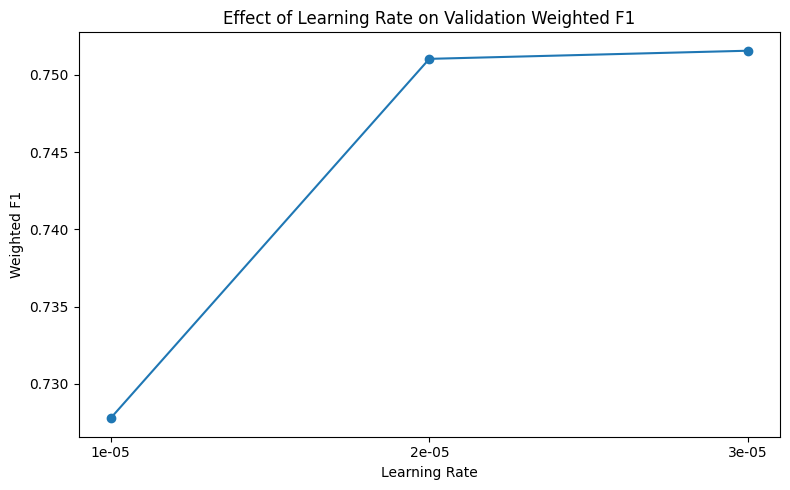

In [75]:
#Visualizing experiments

plt.figure(figsize=(8, 5))

plt.plot(
    experiment_df["learning_rate"].astype(str),
    experiment_df["f1_weighted"],
    marker="o"
)

plt.title("Effect of Learning Rate on Validation Weighted F1")
plt.xlabel("Learning Rate")
plt.ylabel("Weighted F1")

plt.tight_layout()

experiment_plot_path = (
    FIGURES_DIR / "learning_rate_experiment.png"
)

plt.savefig(
    experiment_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [76]:
#Selecting best learning rate

best_experiment = experiment_df.loc[
    experiment_df["f1_weighted"].idxmax()
]

BEST_LR = float(
    best_experiment["learning_rate"]
)

print("Best learning rate:", BEST_LR)
print(
    "Validation weighted F1:",
    best_experiment["f1_weighted"]
)

Best learning rate: 3e-05
Validation weighted F1: 0.7515646780104741


# 10. Final Model Training

The final model configuration is selected using validation performance from the controlled learning-rate experiment.

The test set has not been used during model selection. This protects the test set as an unbiased estimate of final model performance.

The final model is trained using the selected learning rate and the same architecture and preprocessing pipeline.

In [77]:
final_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [81]:
# Calculate warmup steps outside TrainingArguments
total_steps = (len(train_df) // 16) * 3
warmup_steps = int(total_steps * 0.1)

final_args = TrainingArguments(
    # Save temporarily in Colab, NOT Google Drive
    output_dir="/content/xlmr_final_model",

    eval_strategy="epoch",


    save_strategy="no",

    learning_rate=BEST_LR,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,

    num_train_epochs=3,

    weight_decay=0.01,

    # Use the precalculated warmup steps
    warmup_steps=warmup_steps,

    logging_strategy="epoch",

    # No checkpoint = nothing to reload
    load_best_model_at_end=False,

    fp16=torch.cuda.is_available(),

    seed=SEED,
    report_to="none"
)

In [83]:
final_trainer = Trainer(
    model=final_model,
    args=final_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

final_trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision Weighted,Recall Weighted,F1 Weighted
1,0.869449,0.709387,0.688831,0.688975,0.688831,0.688902
2,0.677981,0.630293,0.739260,0.742007,0.739260,0.739170
3,0.557088,0.602613,0.750840,0.754549,0.750840,0.751565


TrainOutput(global_step=2658, training_loss=0.7015058117042008, metrics={'train_runtime': 332.865, 'train_samples_per_second': 127.727, 'train_steps_per_second': 7.985, 'total_flos': 1554994132051752.0, 'train_loss': 0.7015058117042008, 'epoch': 3.0})

# 11. Final Test Evaluation

The test set was kept completely separate from model selection and hyperparameter tuning.

The final model is now evaluated on the held-out test set to estimate how well the system generalizes to unseen Hausa text.

These results represent the final performance reported in the project.

In [84]:
test_results = final_trainer.evaluate(
    tokenized_dataset["test"]
)

test_results

Training Loss,Validation Loss,Epoch,Accuracy,Precision Weighted,Recall Weighted,F1 Weighted
0.557088,0.729799,3,0.707713,0.716831,0.707713,0.706916


{'eval_loss': 0.7297993898391724,
 'eval_accuracy': 0.70771261550066,
 'eval_precision_weighted': 0.7168306872827147,
 'eval_recall_weighted': 0.70771261550066,
 'eval_f1_weighted': 0.7069156977529597}

In [85]:
#Detailed test report

test_predictions = final_trainer.predict(
    tokenized_dataset["test"]
)

test_logits = test_predictions.predictions
test_pred_ids = np.argmax(
    test_logits,
    axis=-1
)

test_true_ids = test_predictions.label_ids

print(
    classification_report(
        test_true_ids,
        test_pred_ids,
        target_names=[
            id2label[i] for i in range(3)
        ],
        digits=4
    )
)

              precision    recall  f1-score   support

    negative     0.6218    0.7749    0.6900      1759
     neutral     0.7097    0.5752    0.6354      1789
    positive     0.8194    0.7755    0.7968      1755

    accuracy                         0.7077      5303
   macro avg     0.7169    0.7085    0.7074      5303
weighted avg     0.7168    0.7077    0.7069      5303



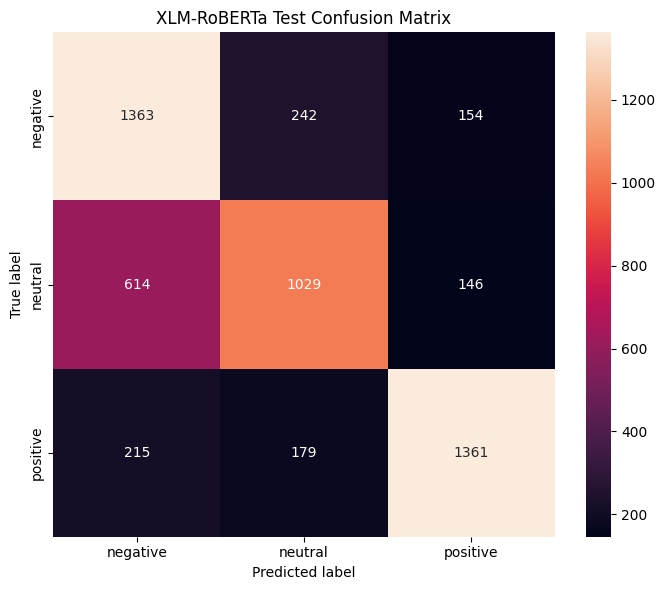

In [87]:
#Final confusion matrix

final_cm = confusion_matrix(
    test_true_ids,
    test_pred_ids
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    xticklabels=[
        id2label[i] for i in range(3)
    ],
    yticklabels=[
        id2label[i] for i in range(3)
    ]
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("XLM-RoBERTa Test Confusion Matrix")

plt.tight_layout()

final_cm_path = (
    FIGURES_DIR / "final_confusion_matrix.png"
)

plt.savefig(
    final_cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [88]:
test_analysis = test_df.copy()

probabilities = torch.softmax(
    torch.tensor(test_logits),
    dim=-1
).numpy()

test_analysis["true_label"] = [
    id2label[i]
    for i in test_true_ids
]

test_analysis["predicted_label"] = [
    id2label[i]
    for i in test_pred_ids
]

test_analysis["confidence"] = probabilities.max(
    axis=1
)

test_analysis["correct"] = (
    test_analysis["true_label"]
    == test_analysis["predicted_label"]
)

errors = test_analysis[
    ~test_analysis["correct"]
].copy()

errors = errors.sort_values(
    "confidence",
    ascending=False
)

display(
    errors[
        [
            "tweet",
            "true_label",
            "predicted_label",
            "confidence"
        ]
    ].head(20)
)

,tweet,true_label,predicted_label,confidence
2914,original baba buharin mu dai ya fi kyau,neutral,positive,0.992553
2837,oh god ke duniya saudiyya ma kenan,neutral,positive,0.992422
4255,ina kyau anan,negative,positive,0.991366
2334,duk kyau da izzar mace namiji yagama da ita,neutral,positive,0.991351
2030,dan matsa naga motar bayanka da kyau,neutral,positive,0.990551
4420,kai abu bai kyau bah gaskia,negative,positive,0.990014
2740,kyau aceh kece mati,neutral,positive,0.989667
3001,munfisu hausa mai kyau gaskiya meye kuma zanbu...,neutral,positive,0.989238
2966,best wishes rahamah koma dai mene ne,neutral,positive,0.989099
4312,innalillahi wainna ilaihi rajiun tsohonnan fa ...,negative,positive,0.988005


## High-Confidence Error Analysis

High-confidence incorrect predictions are particularly useful for qualitative analysis because they show cases where the model strongly preferred the wrong sentiment class.

These examples can reveal limitations related to:

- ambiguous wording
- sarcasm
- context dependence
- code-switching
- spelling variation
- uncommon vocabulary
- negation
- expressions whose sentiment depends on cultural context

The examples are examined qualitatively rather than assuming that every error has the same cause.

In [89]:
high_confidence_errors = errors[
    errors["confidence"] >= 0.80
]

display(
    high_confidence_errors[
        [
            "tweet",
            "true_label",
            "predicted_label",
            "confidence"
        ]
    ].head(15)
)

,tweet,true_label,predicted_label,confidence
2914,original baba buharin mu dai ya fi kyau,neutral,positive,0.992553
2837,oh god ke duniya saudiyya ma kenan,neutral,positive,0.992422
4255,ina kyau anan,negative,positive,0.991366
2334,duk kyau da izzar mace namiji yagama da ita,neutral,positive,0.991351
2030,dan matsa naga motar bayanka da kyau,neutral,positive,0.990551
4420,kai abu bai kyau bah gaskia,negative,positive,0.990014
2740,kyau aceh kece mati,neutral,positive,0.989667
3001,munfisu hausa mai kyau gaskiya meye kuma zanbu...,neutral,positive,0.989238
2966,best wishes rahamah koma dai mene ne,neutral,positive,0.989099
4312,innalillahi wainna ilaihi rajiun tsohonnan fa ...,negative,positive,0.988005


In [90]:
#Successful examples

successful_examples = test_analysis[
    test_analysis["correct"]
].sort_values(
    "confidence",
    ascending=False
)

display(
    successful_examples[
        [
            "tweet",
            "true_label",
            "predicted_label",
            "confidence"
        ]
    ].head(10)
)

,tweet,true_label,predicted_label,confidence
562,i so much loves you aunty rahma inayinki irin ...,positive,positive,0.994296
597,congratulations my ambassador fatan nasara a k...,positive,positive,0.994256
72,congratulations didi congratulations on your g...,positive,positive,0.994247
1522,barka da sallah lightand love️,positive,positive,0.994197
857,ameeeen ameeeen muma munama fatan alkairi,positive,positive,0.994156
1276,barka da sallah rahama sadaumay the almighty g...,positive,positive,0.994146
1176,i like dis response allah ya taimaka,positive,positive,0.994132
816,congratulations to you mai rariya,positive,positive,0.994114
774,kai wallahi naji dadi sosai wallahi cant wait ...,positive,positive,0.994079
1564,my screen goddess in sha allah ranar friday za...,positive,positive,0.994065


In [91]:
#Saving error analysis

error_analysis_path = (
    RESULTS_DIR / "error_analysis.csv"
)

errors[
    [
        "tweet",
        "true_label",
        "predicted_label",
        "confidence"
    ]
].to_csv(
    error_analysis_path,
    index=False
)

print(
    "Saved:",
    error_analysis_path
)

Saved: /content/drive/MyDrive/hausa_sentiment_classifier/results/error_analysis.csv


In [92]:
#Save final model

FINAL_MODEL_PATH = MODEL_DIR / "xlmr_hausa_sentiment"

final_trainer.save_model(
    str(FINAL_MODEL_PATH)
)

tokenizer.save_pretrained(
    str(FINAL_MODEL_PATH)
)

print(
    "Final model saved to:",
    FINAL_MODEL_PATH
)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Final model saved to: /content/drive/MyDrive/hausa_sentiment_classifier/models/xlmr_hausa_sentiment


In [93]:
#Test inference

def predict_sentiment(text):
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH
    )

    inputs = {
        key: value.to(final_trainer.model.device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = final_trainer.model(**inputs)

    probabilities = torch.softmax(
        outputs.logits,
        dim=-1
    )[0]

    prediction = torch.argmax(
        probabilities
    ).item()

    return {
        "sentiment": id2label[prediction],
        "confidence": float(
            probabilities[prediction]
        )
    }

In [94]:
example = train_df.iloc[0]["tweet"]

print("Input:")
print(example)

print("\nPrediction:")
print(predict_sentiment(example))

Input:
@user Da kudin da Arewa babu wani abin azo agani da yayi wa alummah allah ya isa yacucemu wlh yarikitamana kasa yarikitamana kasuwanci harkar ilimi harkar lfy hanyoyi babu lantarki dasuransu komai yalalace ga cinhanci da rashawa a fili ko ina a Nigeria jamiyaryar su tabataman mlm 😭🗣

Prediction:
{'sentiment': 'negative', 'confidence': 0.9553718566894531}


In [95]:
#Test multiple inputs

examples = [
    train_df.iloc[0]["tweet"],
    train_df.iloc[100]["tweet"],
    train_df.iloc[500]["tweet"]
]

for text in examples:
    result = predict_sentiment(text)

    print("=" * 70)
    print("Text:", text)
    print("Prediction:", result["sentiment"])
    print("Confidence:", round(result["confidence"], 4))

Text: @user Da kudin da Arewa babu wani abin azo agani da yayi wa alummah allah ya isa yacucemu wlh yarikitamana kasa yarikitamana kasuwanci harkar ilimi harkar lfy hanyoyi babu lantarki dasuransu komai yalalace ga cinhanci da rashawa a fili ko ina a Nigeria jamiyaryar su tabataman mlm 😭🗣
Prediction: negative
Confidence: 0.9554
Text: @user Hakika. Late comer badan azziki bane bazan mantaba antaba yimin kof daya wallahi yadda naji araina kamar namutu amma gashi ina rayuwa cikin kunci dalilin rashin masoyiyata Allah sarki mutuniyar kirki baban tane me son abin Duniya 😭
Prediction: negative
Confidence: 0.753
Text: @user Shi dai wanga mutum bai gajiya da qarya! 🤔
Prediction: negative
Confidence: 0.9708
